In [23]:
# --- 1. Imports, data, objective directions, splits -------------------------
import pandas as pd
import torch

torch.set_default_dtype(torch.double)          # BoTorch wants float64
torch.manual_seed(42)

DATA = "SDL_case_studies/inorganic_materials/case2/Dataset"   # note: capital D
inputs = pd.read_csv(f"{DATA}/inputs.csv", skipinitialspace=True)
outputs = pd.read_csv(f"{DATA}/outputs.csv", skipinitialspace=True)

# 22 input rows are exact duplicates; dropping them keeps pool bookkeeping sane
keep = ~inputs.duplicated()
inputs = inputs[keep].reset_index(drop=True)
outputs = outputs[keep].reset_index(drop=True)

# Sign per objective so that EVERY objective is maximised internally.
# Ep: maximise, EFWHM: minimise (narrow line), PLQY: maximise.  <-- check this!
SIGN = torch.tensor([1.0, -1.0, 1.0])
OBJ_NAMES = list(outputs.columns)

X_all = torch.tensor(inputs.to_numpy())
Y_all = torch.tensor(outputs.to_numpy()) * SIGN

# No holdout split any more: with regret as the metric, every unsampled row is
# a legitimate candidate, so they all go in the pool.
N_INIT = 20
perm = torch.randperm(len(X_all))
init_idx, pool_idx = perm[:N_INIT], perm[N_INIT:]

print(f"inputs {tuple(X_all.shape)}  outputs {tuple(Y_all.shape)}")
print(f"init {len(init_idx)}   pool {len(pool_idx)}")

inputs (1277, 5)  outputs (1277, 3)
init 20   pool 1257


In [24]:
# --- 2. Surrogate + a reference point shared by every replicate -------------
from botorch.fit import fit_gpytorch_mll
from botorch.models import ModelListGP, SingleTaskGP
from botorch.models.transforms import Normalize, Standardize
from botorch.utils.multi_objective.box_decompositions.dominated import DominatedPartitioning
from gpytorch.mlls import SumMarginalLogLikelihood


def build_and_fit(X, Y):
    """Independent GP per objective. Normalize/Standardize are what make the
    MLL fit converge -- without them scipy_minimize returns ABNORMAL."""
    models = [
        SingleTaskGP(
            X,
            Y[:, i : i + 1],
            input_transform=Normalize(d=X.shape[-1]),
            outcome_transform=Standardize(m=1),
        )
        for i in range(Y.shape[-1])
    ]
    model = ModelListGP(*models)
    fit_gpytorch_mll(SumMarginalLogLikelihood(model.likelihood, model))
    return model


# Reference point derived from the FULL dataset, not from one run's initial
# sample -- it must be identical across replicates or the hypervolumes are not
# on a common scale and the error bands are meaningless.
span = Y_all.max(dim=0).values - Y_all.min(dim=0).values
ref_point = Y_all.min(dim=0).values - 0.01 * span

# Hypervolume of the true Pareto front of the whole dataset = the regret floor
hv_max = DominatedPartitioning(ref_point=ref_point, Y=Y_all).compute_hypervolume().item()
print("ref_point:", [f"{v:.3f}" for v in ref_point.tolist()])
print(f"hv_max:    {hv_max:.4g}")

ref_point: ['1.831', '-0.200', '-0.001']
hv_max:    0.06029


In [25]:
# --- 3. One campaign = one replicate; repeat over seeds ---------------------
try:
    from botorch.acquisition.multi_objective.logei import (
        qLogNoisyExpectedHypervolumeImprovement as qNEHVI,
    )
except ImportError:  # older BoTorch
    from botorch.acquisition.multi_objective import (
        qNoisyExpectedHypervolumeImprovement as qNEHVI,
    )

from botorch.optim import optimize_acqf_discrete
from tqdm.auto import tqdm

N_STEPS = 50
N_SEEDS = 10          # replicates. 10 is the usual minimum for a sane band.


def run_campaign(seed, strategy="bo"):
    """Run one full BO campaign from scratch. The replicate unit is the whole
    campaign: a fresh random initial design + fresh acqf sampling."""
    torch.manual_seed(seed)
    perm = torch.randperm(len(X_all))
    init_idx, pool_idx = perm[:N_INIT], perm[N_INIT:]

    train_X, train_Y = X_all[init_idx].clone(), Y_all[init_idx].clone()
    pool_X, pool_Y = X_all[pool_idx].clone(), Y_all[pool_idx].clone()
    hv = []

    # one bar per replicate, so you can see progress within a campaign
    bar = tqdm(range(N_STEPS), desc=f"{strategy} seed {seed:>2}", leave=True)
    for _ in bar:
        hv.append(
            DominatedPartitioning(ref_point=ref_point, Y=train_Y).compute_hypervolume().item()
        )
        bar.set_postfix(hv=f"{hv[-1]:.3g}", pool=len(pool_X))

        if strategy == "bo":
            model = build_and_fit(train_X, train_Y)   # fit BEFORE building the acqf
            acq = qNEHVI(model=model, ref_point=ref_point.tolist(),
                         X_baseline=train_X, prune_baseline=True)
            new_X, _ = optimize_acqf_discrete(acq, q=1, choices=pool_X, max_batch_size=256)
            idx = int((pool_X == new_X).all(dim=1).nonzero()[0])
        else:                                          # random-sampling baseline
            idx = int(torch.randint(len(pool_X), (1,)))

        train_X = torch.cat([train_X, pool_X[idx : idx + 1]])
        train_Y = torch.cat([train_Y, pool_Y[idx : idx + 1]])
        mask = torch.arange(len(pool_X)) != idx
        pool_X, pool_Y = pool_X[mask], pool_Y[mask]

    hv.append(DominatedPartitioning(ref_point=ref_point, Y=train_Y).compute_hypervolume().item())
    return hv, train_X, train_Y


n_train = list(range(N_INIT, N_INIT + N_STEPS + 1))
curves = {}

for strategy in ("bo", "random"):
    runs = []
    for seed in range(N_SEEDS):
        hv, tX, tY = run_campaign(seed, strategy)
        runs.append(hv)
        if strategy == "bo" and seed == 0:
            train_X, train_Y = tX, tY      # keep one run for the per-run panels
    curves[strategy] = torch.tensor(runs)  # (N_SEEDS, N_STEPS + 1)

regret = {k: hv_max - v for k, v in curves.items()}
for k, v in regret.items():
    print(f"{k:>6}: final regret {v[:, -1].median():.4g}  "
          f"(IQR {v[:, -1].quantile(0.25):.4g} - {v[:, -1].quantile(0.75):.4g})")

/home/gabri/Documents/00_CodeVault/03_PhD/WinterSchool/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
random seed  9: 100%|██████████| 50/50 [00:00<00:00, 198.34it/s, hv=0.0421, pool=1208]


    bo: final regret 0.008949  (IQR 0.008461 - 0.01079)
random: final regret 0.01513  (IQR 0.01439 - 0.01797)


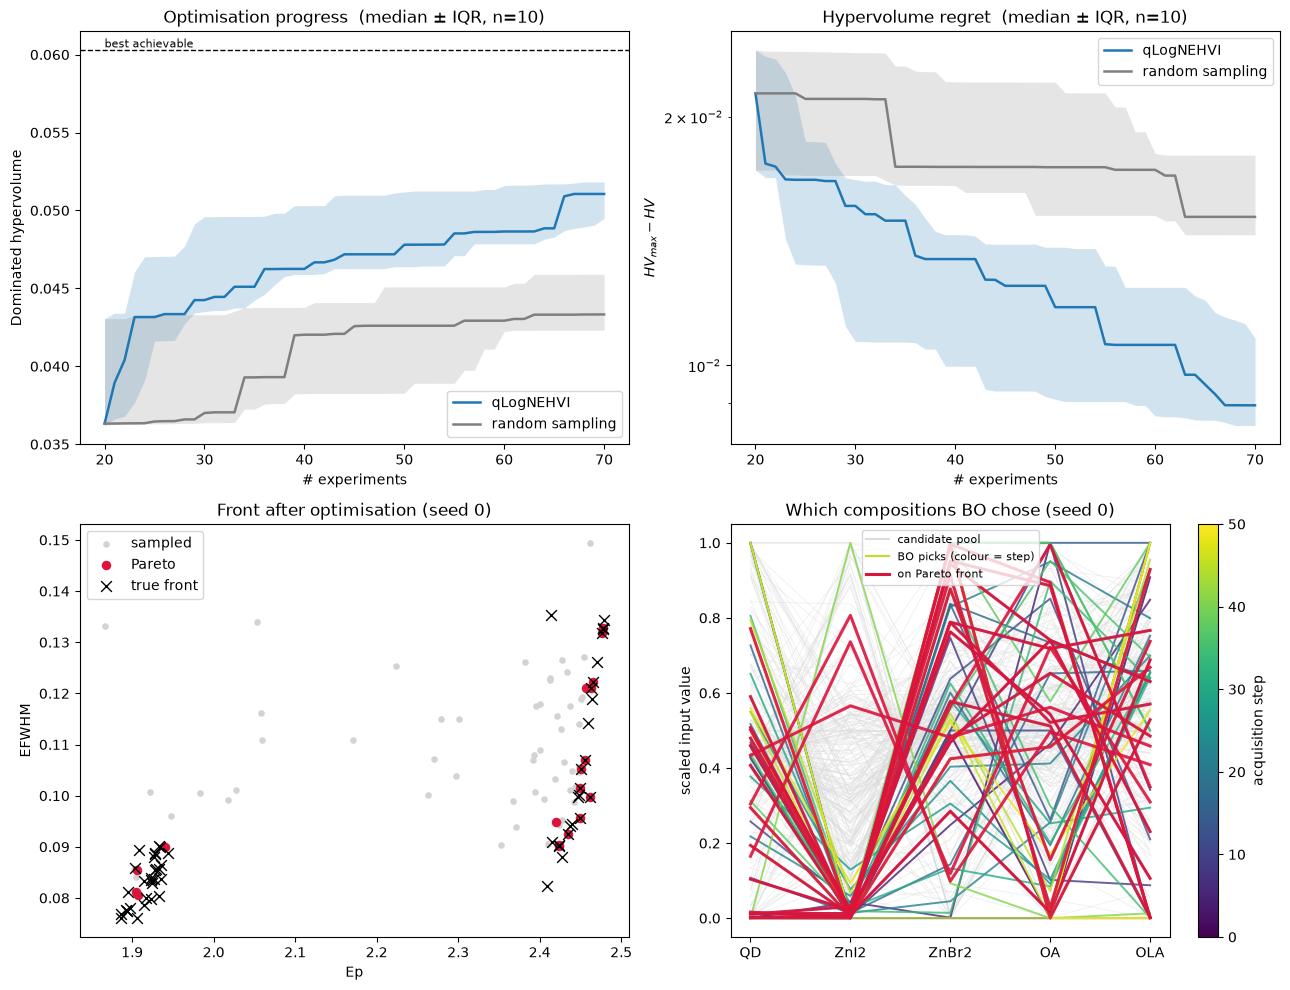

In [26]:
# --- 4. Visuals: median over replicates with inter-quartile bands -----------
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize as ColourNorm
from matplotlib.lines import Line2D
from botorch.utils.multi_objective.pareto import is_non_dominated

STYLE = {"bo": ("tab:blue", "qLogNEHVI"), "random": ("tab:grey", "random sampling")}


def band(ax, x, runs, colour, label):
    """Median line + inter-quartile band across replicates. Median/IQR rather
    than mean/SD: these curves are bounded and skewed, so SD would imply
    symmetric error and can run past the achievable ceiling."""
    med = runs.median(dim=0).values
    ax.plot(x, med, color=colour, lw=1.8, label=label)
    ax.fill_between(x, runs.quantile(0.25, dim=0), runs.quantile(0.75, dim=0),
                    color=colour, alpha=0.2, lw=0)


fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# -- hypervolume vs experiments
for k, (colour, label) in STYLE.items():
    band(axes[0, 0], n_train, curves[k], colour, label)
axes[0, 0].axhline(hv_max, ls="--", c="black", lw=1)
axes[0, 0].annotate("best achievable", (n_train[0], hv_max), fontsize=8, va="bottom")
axes[0, 0].set(xlabel="# experiments", ylabel="Dominated hypervolume",
               title=f"Optimisation progress  (median $\\pm$ IQR, n={N_SEEDS})")
axes[0, 0].legend()

# -- regret, log scale
for k, (colour, label) in STYLE.items():
    band(axes[0, 1], n_train, regret[k], colour, label)
if min(r.min().item() for r in regret.values()) > 0:
    axes[0, 1].set_yscale("log")
axes[0, 1].set(xlabel="# experiments", ylabel="$HV_{max} - HV$",
               title=f"Hypervolume regret  (median $\\pm$ IQR, n={N_SEEDS})")
axes[0, 1].legend()

# -- Pareto front of a single representative run (seed 0)
Y_orig = train_Y * SIGN
front = is_non_dominated(train_Y)
axes[1, 0].scatter(Y_orig[~front, 0], Y_orig[~front, 1], s=14, c="lightgrey", label="sampled")
axes[1, 0].scatter(Y_orig[front, 0], Y_orig[front, 1], s=34, c="crimson", label="Pareto")
Y_true = (Y_all * SIGN)[is_non_dominated(Y_all)]
axes[1, 0].scatter(Y_true[:, 0], Y_true[:, 1], s=60, marker="x", c="black",
                   linewidths=1.0, label="true front")
axes[1, 0].set(xlabel=OBJ_NAMES[0], ylabel=OBJ_NAMES[1], title="Front after optimisation (seed 0)")
axes[1, 0].legend()

# -- parallel coordinates for that same run: one axis per input, nothing projected
ax = axes[1, 1]
IN_NAMES = list(inputs.columns)
lo, hi = X_all.min(dim=0).values, X_all.max(dim=0).values
nz = lambda X: ((X - lo) / (hi - lo)).numpy()
xs = range(X_all.shape[-1])

ax.plot(xs, nz(X_all[torch.randperm(len(X_all))[:250]]).T,
        color="gainsboro", lw=0.6, alpha=0.45, zorder=1)

acq_rows = nz(train_X[N_INIT:])
cmap = plt.get_cmap("viridis")
for k, row in enumerate(acq_rows):
    ax.plot(xs, row, color=cmap(k / max(len(acq_rows) - 1, 1)), lw=1.4, alpha=0.8, zorder=3)

ax.plot(xs, nz(train_X[front]).T, color="crimson", lw=2.2, alpha=0.9, zorder=4)
ax.set_xticks(list(xs), IN_NAMES)
ax.set(ylabel="scaled input value", title="Which compositions BO chose (seed 0)")
ax.legend(handles=[Line2D([], [], color="gainsboro", label="candidate pool"),
                   Line2D([], [], color=cmap(0.9), label="BO picks (colour = step)"),
                   Line2D([], [], color="crimson", lw=2.2, label="on Pareto front")],
          fontsize=8, loc="best")
fig.colorbar(ScalarMappable(norm=ColourNorm(0, len(acq_rows)), cmap=cmap),
             ax=ax, label="acquisition step")

fig.tight_layout()
plt.show()

In [27]:
# --- 5. Knowledge Gradient for MOBO (ParEGO-style scalarisation) ------------
# BoTorch has no native multi-objective KG: qKnowledgeGradient is single
# objective. The standard workaround (ParEGO) is to draw random Chebyshev
# weights each step, collapse the 3 objectives to a scalar, and run KG on that.
# Different weights each step => the front gets covered over many steps.
from botorch.acquisition.knowledge_gradient import qKnowledgeGradient
from botorch.acquisition.objective import GenericMCObjective
from botorch.utils.multi_objective.scalarization import get_chebyshev_scalarization
from botorch.utils.sampling import sample_simplex

# KG is far more expensive than NEHVI: every candidate requires an inner
# optimisation over num_fantasies fantasy models. These three knobs are the
# cost/quality dial -- raise them if you have time, lower them if you don't.
KG_CANDIDATES = 64     # random subsample of the pool scored each step
KG_FANTASIES = 8       # fantasy models per candidate
KG_RESTARTS, KG_RAW = 2, 32    # inner-optimisation budget

bounds = torch.stack([X_all.min(dim=0).values, X_all.max(dim=0).values])


def run_campaign_kg(seed):
    """Same protocol as run_campaign() so the curves are directly comparable:
    same N_INIT, same N_STEPS, same ref_point, same seed semantics."""
    torch.manual_seed(seed)
    perm = torch.randperm(len(X_all))
    init_idx, pool_idx = perm[:N_INIT], perm[N_INIT:]

    train_X, train_Y = X_all[init_idx].clone(), Y_all[init_idx].clone()
    pool_X, pool_Y = X_all[pool_idx].clone(), Y_all[pool_idx].clone()
    hv = []

    bar = tqdm(range(N_STEPS), desc=f"kg seed {seed:>2}", leave=True)
    for _ in bar:
        hv.append(
            DominatedPartitioning(ref_point=ref_point, Y=train_Y).compute_hypervolume().item()
        )
        bar.set_postfix(hv=f"{hv[-1]:.3g}", pool=len(pool_X))

        model = build_and_fit(train_X, train_Y)

        # fresh random weights -> a different corner of the front each step
        weights = sample_simplex(d=train_Y.shape[-1]).squeeze()
        objective = GenericMCObjective(
            get_chebyshev_scalarization(weights=weights, Y=train_Y)
        )
        acq = qKnowledgeGradient(model=model, num_fantasies=KG_FANTASIES,
                                 objective=objective)

        # qKG is a one-shot acqf, so optimize_acqf_discrete cannot be used.
        # .evaluate() runs the proper inner optimisation per candidate; we
        # score a random subsample of the pool to keep that affordable.
        sub = torch.randperm(len(pool_X))[:KG_CANDIDATES]
        vals = acq.evaluate(pool_X[sub].unsqueeze(1), bounds=bounds,
                            num_restarts=KG_RESTARTS, raw_samples=KG_RAW)
        idx = int(sub[vals.argmax()])

        train_X = torch.cat([train_X, pool_X[idx : idx + 1]])
        train_Y = torch.cat([train_Y, pool_Y[idx : idx + 1]])
        mask = torch.arange(len(pool_X)) != idx
        pool_X, pool_Y = pool_X[mask], pool_Y[mask]

    hv.append(DominatedPartitioning(ref_point=ref_point, Y=train_Y).compute_hypervolume().item())
    return hv, train_X, train_Y


KG_SEEDS = 3      # start small: KG is ~10-50x slower per step than NEHVI

runs = []
for seed in range(KG_SEEDS):
    hv, _, _ = run_campaign_kg(seed)
    runs.append(hv)

curves["kg"] = torch.tensor(runs)
regret["kg"] = hv_max - curves["kg"]
print(f"    kg: final regret {regret['kg'][:, -1].median():.4g}  "
      f"(n={KG_SEEDS} replicates)")

kg seed  2: 100%|██████████| 50/50 [26:42<00:00, 32.06s/it, hv=0.0554, pool=1208]

    kg: final regret 0.008242  (n=3 replicates)


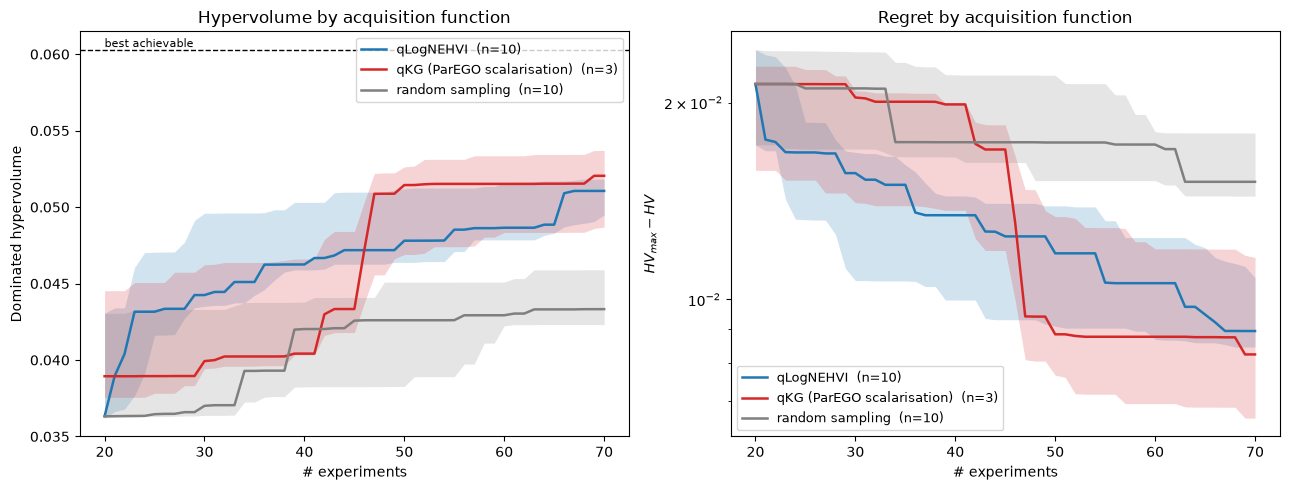

method                         final regret (median)                         IQR    n
qLogNEHVI                                   0.008949      0.008461 - 0.01079        10
qKG (ParEGO scalarisation)                  0.008242      0.006588 - 0.0116          3
random sampling                              0.01513       0.01439 - 0.01797        10


In [28]:
# --- 6. Acquisition-function comparison: NEHVI vs KG vs random -------------
STYLE3 = {
    "bo":     ("tab:blue",   "qLogNEHVI"),
    "kg":     ("tab:red",    "qKG (ParEGO scalarisation)"),
    "random": ("tab:grey",   "random sampling"),
}

fig, (ax_hv, ax_rg) = plt.subplots(1, 2, figsize=(13, 5))

for k, (colour, label) in STYLE3.items():
    n = len(curves[k])
    band(ax_hv, n_train, curves[k], colour, f"{label}  (n={n})")
    band(ax_rg, n_train, regret[k], colour, f"{label}  (n={n})")

ax_hv.axhline(hv_max, ls="--", c="black", lw=1)
ax_hv.annotate("best achievable", (n_train[0], hv_max), fontsize=8, va="bottom")
ax_hv.set(xlabel="# experiments", ylabel="Dominated hypervolume",
          title="Hypervolume by acquisition function")
ax_hv.legend(fontsize=9)

if min(r.min().item() for r in regret.values()) > 0:
    ax_rg.set_yscale("log")
ax_rg.set(xlabel="# experiments", ylabel="$HV_{max} - HV$",
          title="Regret by acquisition function")
ax_rg.legend(fontsize=9)

fig.tight_layout()
plt.show()

# Replicate counts differ between methods, so state them rather than hiding it.
print(f"{'method':<28}{'final regret (median)':>24}{'IQR':>28}{'n':>5}")
for k, (_, label) in STYLE3.items():
    f = regret[k][:, -1]
    print(f"{label:<28}{f.median():>24.4g}"
          f"{f.quantile(0.25):>14.4g} - {f.quantile(0.75):<12.4g}{len(f):>5}")